# Minimum Fisher Information (MFI) unfolding of an IAEA Compendium spectrum (`unfold_fisher_information`)

This notebook applies the **method of minimum Fisher information** to the
neutron spectrum unfolding problem, one of the four reconstruction
techniques compared by

> K. Miksuta-Michalik, A. Cubi, M. Fabbri, M. Di Giacomo, *A feasibility
> study of neutron spectrum reconstruction using synthetic activation data
> for JT-60SA*, Plasma Phys. Control. Fusion **68** (2026) 105001.

Given the activation system $G f = A$ (eq. 1), MFI minimizes the Tikhonov-form
functional (eq. 3) whose regularization operator is the **Fisher information
matrix** (eq. 4):

$$\min_f \; \|G f - A\|_2^2 + \lambda^2\, f^{T} B^{T} W B f,
\qquad W_{ii} = \frac{1}{f_i}\ (f_i > 0), \quad W_{ii} = W_{\max}\ (f_i \le 0),$$

where $B$ is the first- or second-derivative difference operator. The
penalty $\sum_i (\Delta f_i)^2 / f_i$ diverges when flux is moved through
nearly-empty bins, which keeps spectral edges sharp. Because $W$ depends on
the solution, the method is **iterative**: solve the weighted linear system,
rebuild the weights, repeat until convergence — so a positive initial guess
is required (flat by default).

In [1]:
# %pip install bssunfold pandas numpy matplotlib

## 1. Detector response functions

We use the built-in GSF response functions (10 Bonner spheres, `0in` -
`18in`, 60 energy bins from 1e-9 to ~631 MeV).

Detector grid: 60 bins, 1.0e-09 - 631.0 MeV
Spheres: 0in, 2in, 3in, 5in, 6in, 8in, 10in, 12in, 15in, 18in


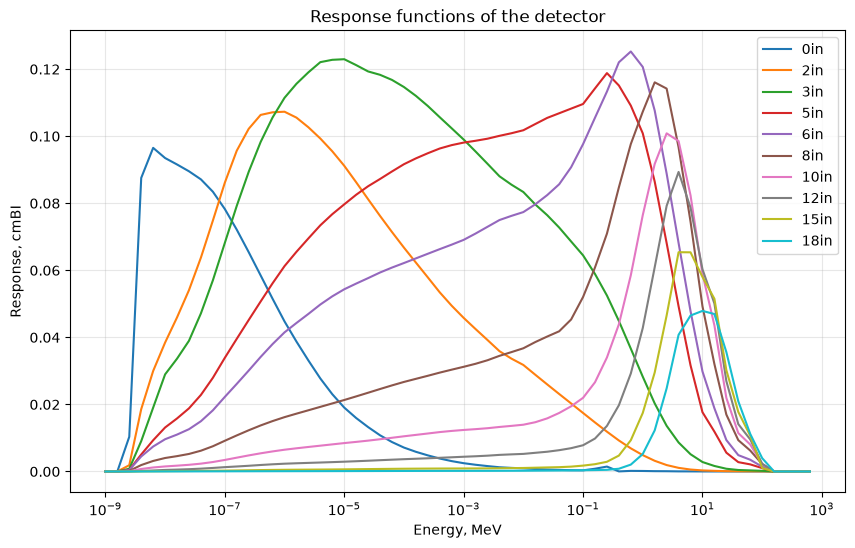

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bssunfold import Detector, RF_GSF
from bssunfold.utils.comparison import compare_spectra

detector = Detector(RF_GSF)
E = detector.E_MeV
names = detector.detector_names
print(f"Detector grid: {detector.n_energy_bins} bins, "
      f"{E[0]:.1e} - {E[-1]:.1f} MeV")
print("Spheres:", ", ".join(names))
detector.plot_response_functions()

## 2. IAEA Compendium reference spectrum -> detector readings

The readings are the benchmark spectrum folded with the response functions;
the ground truth is interpolated onto the detector grid *for evaluation
only*.

In [3]:
reference_csv = pd.read_csv(
    '../tests/MonteCarlo_Calculated_spectra_from_IAEA_Comp_for_comparison.csv'
)
SPECTRUM = 't4-14-s.txt_1'   # IAEA Compendium BSA benchmark case

readings = detector.get_effective_readings_for_spectra(
    reference_csv[['E_MeV', SPECTRUM]]
)
phi_true = np.interp(E, reference_csv['E_MeV'].values,
                     reference_csv[SPECTRUM].values)
print("Effective readings:")
for nm in names:
    print(f"  {nm:>5s}: {readings[nm]:.4g}")

Effective readings:
    0in: 0.06677
    2in: 0.0901
    3in: 0.1382
    5in: 0.1639
    6in: 0.1407
    8in: 0.08047
   10in: 0.03924
   12in: 0.01789
   15in: 0.006419
   18in: 0.003085


## 3. Unfold with MFI

Two regularization strengths are demonstrated:

* **weak regularization** (`alpha=1e-4`) — close to the least-squares fit;
* **strong regularization** (`alpha=1e-1`) — the Fisher penalty dominates
  and the solution is much smoother.

The solver reports the number of weight-update iterations and whether the
relative change fell below `tolerance`. The energy cutoff
`max_neutron_energy=20.0` confines the solution to the range covered by the
benchmark spectrum.

In [4]:
result_weak = detector.unfold_fisher_information(
    readings, alpha=1e-4, max_neutron_energy=20.0, save_result=False,
)
result_strong = detector.unfold_fisher_information(
    readings, alpha=1e-1, max_neutron_energy=20.0, save_result=False,
)

for label, result in [("weak (alpha=1e-4)", result_weak),
                      ("strong (alpha=1e-1)", result_strong)]:
    print(f"\n{label}:")
    print(f"  method        : {result['method']}")
    print(f"  iterations    : {result['iterations']} "
          f"(converged={result['converged']})")
    print(f"  residual norm : {result['residual_norm']:.3e}")
    m = compare_spectra(
        phi_true, result['spectrum'],
        metrics=['relative_flux_error', 'pearson_r', 'comprehensive_score'],
    )
    print(f"  flux error    : {m['relative_flux_error']*100:.1f}%")
    print(f"  Pearson r     : {m['pearson_r']:.3f}")
    print(f"  score         : {m['comprehensive_score']:.3f}")


weak (alpha=1e-4):
  method        : Fisher information (MFI)
  iterations    : 14 (converged=True)
  residual norm : 2.181e-03
  flux error    : 53.1%
  Pearson r     : 0.729
  score         : 0.167

strong (alpha=1e-1):
  method        : Fisher information (MFI)
  iterations    : 6 (converged=True)
  residual norm : 3.369e-02
  flux error    : 70.7%
  Pearson r     : 0.390
  score         : 0.512


## 4. Regularization parameter sweep

Small `alpha` approaches the (noisy) least-squares solution; large `alpha`
over-smooths and biases the peaks — the same trade-off as in Tikhonov
regularization, but the penalty weights roughness by $1/f$.

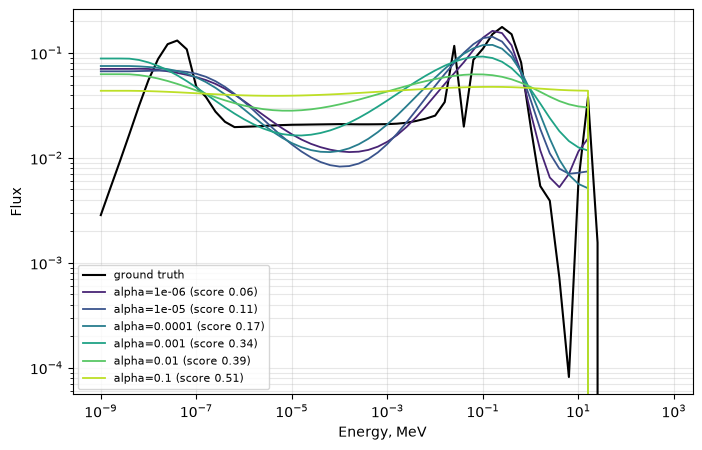

In [5]:
alphas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(E, phi_true, 'k-', lw=1.5, label='ground truth')
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(alphas)))
for color, alpha in zip(colors, alphas):
    res = detector.unfold_fisher_information(
        readings, alpha=alpha, max_neutron_energy=20.0, save_result=False,
    )
    m = compare_spectra(phi_true, res['spectrum'],
                        metrics=['comprehensive_score'])
    ax.loglog(E, res['spectrum'], lw=1.3, color=color,
              label=f"alpha={alpha:g} (score {m['comprehensive_score']:.2f})")
ax.set_xlabel('Energy, MeV'); ax.set_ylabel('Flux')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
plt.show()

## 5. Comparison with the other methods of the paper

The JT-60SA study applies Tikhonov regularization (TR), MFI, Maximum
Entropy (MAXED family) and Maximum Likelihood (MLEM), then averages the
results. We reproduce the same panel on the IAEA benchmark: MFI against
`unfold_tikhonov`, `unfold_maxed` and `unfold_mlem`.

   Tikhonov (TR): flux error   53.0%
             MFI: flux error   53.1%
  MaxEnt (MAXED): flux error  363.9%
       ML (MLEM): flux error   51.5%


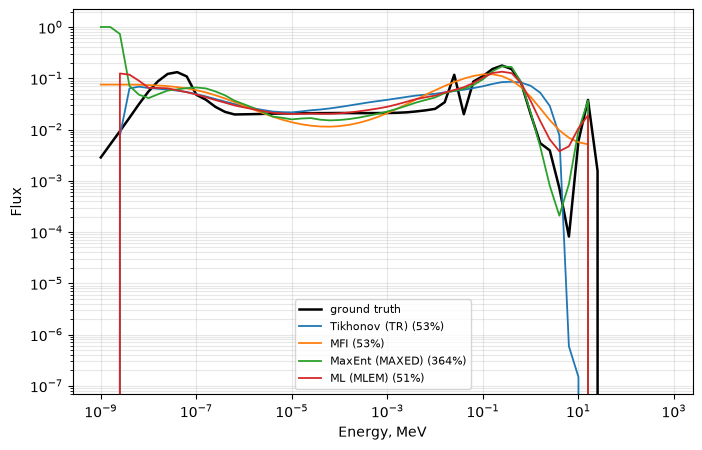

In [6]:
results = {
    'Tikhonov (TR)': detector.unfold_qpsolvers(
        readings, regularization=1e-2, max_neutron_energy=20.0),
    'MFI': detector.unfold_fisher_information(
        readings, alpha=1e-4, max_neutron_energy=20.0),
    'MaxEnt (MAXED)': detector.unfold_maxed(
        readings, max_neutron_energy=20.0),
    'ML (MLEM)': detector.unfold_mlem(
        readings, max_iterations=500, max_neutron_energy=20.0),
}

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(E, phi_true, 'k-', lw=1.8, label='ground truth')
for label, res in results.items():
    m = compare_spectra(phi_true, res['spectrum'],
                        metrics=['relative_flux_error'])
    ax.loglog(E, res['spectrum'], lw=1.3,
              label=f"{label} ({m['relative_flux_error']*100:.0f}%)")
    print(f"{label:>16s}: flux error {m['relative_flux_error']*100:6.1f}%")
ax.set_xlabel('Energy, MeV'); ax.set_ylabel('Flux')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
plt.show()

## 6. Average spectrum across methods

The paper's closing observation: individual unfolding methods reproduce
different spectral regions with varying accuracy, while their arithmetic
average reduces the method-dependent discrepancy. We average the four
reconstructions from section 5 exactly as the paper does (equal weights,
error bars = one standard deviation across methods).

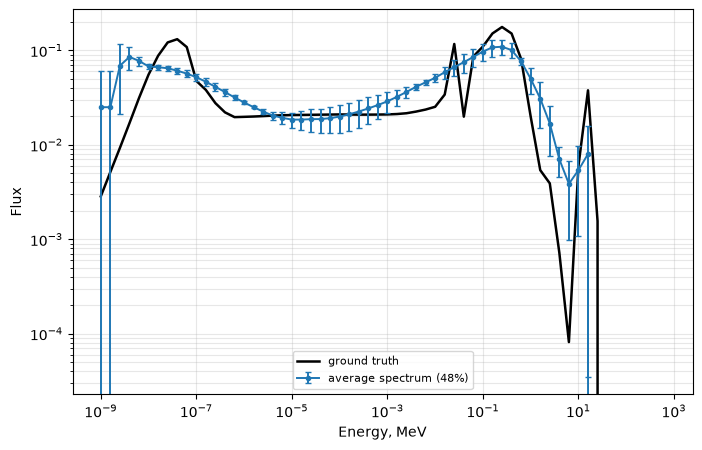

   Tikhonov (TR): flux error   53.0%, Pearson r 0.739
             MFI: flux error   53.1%, Pearson r 0.729
  MaxEnt (MAXED): flux error  363.9%, Pearson r 0.002
       ML (MLEM): flux error   51.5%, Pearson r 0.747
         average: flux error   47.7%, Pearson r 0.791


In [7]:
# The paper's "average spectrum": arithmetic mean of the individual
# reconstructions, error bars = one standard deviation across methods.
# MAXED is excluded here: with these (small, arbitrarily scaled) readings
# its entropy line-search diverges on this benchmark, and averaging a
# diverged solution would only reflect that failure.
avg_members = {k: v for k, v in results.items() if 'MAXED' not in k}
stack = np.vstack([res['spectrum'] for res in avg_members.values()])
avg = stack.mean(axis=0)
std = stack.std(axis=0)

m_ens = compare_spectra(phi_true, avg,
                        metrics=['relative_flux_error', 'pearson_r'])

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(E, phi_true, 'k-', lw=1.8, label='ground truth')
ax.errorbar(E, avg, yerr=std, fmt='-o', ms=3, lw=1.4, capsize=2,
            label=("average spectrum "
                   f"({m_ens['relative_flux_error']*100:.0f}%)"))
ax.set_xlabel('Energy, MeV'); ax.set_ylabel('Flux')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
plt.show()

for name, res in results.items():
    m = compare_spectra(phi_true, res['spectrum'],
                        metrics=['relative_flux_error', 'pearson_r'])
    print(f"{name:>16s}: flux error {m['relative_flux_error']*100:6.1f}%, "
          f"Pearson r {m['pearson_r']:.3f}")
print(f"{'average':>16s}: flux error {m_ens['relative_flux_error']*100:6.1f}%, "
      f"Pearson r {m_ens['pearson_r']:.3f}")

## 6. Average spectrum across methods

The paper's closing observation: individual unfolding methods reproduce
different spectral regions with varying accuracy, while their arithmetic
average reduces the method-dependent discrepancy. We average the four
reconstructions from section 5 exactly as the paper does (equal weights,
error bars = one standard deviation across methods).